# ELE680 – Long-Horizon Forecasting
## 03 – Baseline Models: Persistence and DLinear

**Group:** 2  
**Dataset:** ETTh1 (Electricity Transformer Temperature)

### Objective
Implement and evaluate two forecasting models:
1. Persistence (Last Value) baseline
2. DLinear neural network

The models will use a 96-hour input window to predict
the following 96 hours.

### Evaluation
Model performance will be measured using:
- Mean Squared Error (MSE)
- Mean Absolute Error (MAE)

The results will later be compared with a Transformer model
to investigate whether increased model complexity
improves long-horizon forecasting accuracy.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Libraries imported successfully!
PyTorch version: 2.5.1+cu118
CUDA available: True


## 2. Loading Preprocessed ETTh1 Data

Load the preprocessed training, validation, and testing
tensors generated in the preprocessing notebook.

Using the same preprocessed data ensures a fair
comparison between Persistence, DLinear, and Transformer.

In [2]:
from pathlib import Path

# Path to the saved preprocessing file
data_path = Path("processed_data/ETTh1_preprocessed.pt")

# Load the saved data
data = torch.load(data_path, map_location="cpu", weights_only=True)

# Extract training tensors
X_train = data["X_train"]
y_train = data["y_train"]

# Extract validation tensors
X_val = data["X_val"]
y_val = data["y_val"]

# Extract testing tensors
X_test = data["X_test"]
y_test = data["y_test"]

# Extract metadata
feature_cols = data["feature_cols"]
ot_index = data["target_index"]
input_len = data["input_len"]
pred_len = data["pred_len"]

print("Preprocessed data loaded successfully!")

print("\nTraining:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nInput features:", feature_cols)
print("OT index:", ot_index)
print("Input length:", input_len)
print("Prediction length:", pred_len)

Preprocessed data loaded successfully!

Training: torch.Size([8449, 96, 7]) torch.Size([8449, 96])
Validation: torch.Size([2785, 96, 7]) torch.Size([2785, 96])
Testing: torch.Size([2785, 96, 7]) torch.Size([2785, 96])

Input features: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
OT index: 6
Input length: 96
Prediction length: 96


## 3. Persistence (Last Value) Baseline

The Persistence baseline predicts that the future oil
temperature remains equal to the last observed oil temperature.

This model requires no training and provides a reference
for evaluating DLinear and Transformer.

In [3]:
def persistence_forecast(X, target_index, pred_len):
    """
    Predict future values using the last observed target value.

    Parameters:
        X: Input tensor (batch_size, input_len, num_features)
        target_index: Index of the target variable (OT)
        pred_len: Number of future hours to predict

    Returns:
        Predictions (batch_size, pred_len)
    """

    # Extract the last observed OT value
    last_value = X[:, -1, target_index]

    # Repeat the last value for all future hours
    predictions = last_value.unsqueeze(1).repeat(1, pred_len)

    return predictions


# Test the function using the first 3 training samples
X_sample = X_train[:3]

y_pred_sample = persistence_forecast(
    X_sample,
    target_index=ot_index,
    pred_len=pred_len
)

print("Input shape:", X_sample.shape)
print("Prediction shape:", y_pred_sample.shape)

print("\nLast observed OT values:")
print(X_sample[:, -1, ot_index])

print("\nFirst 5 predictions for sample 1:")
print(y_pred_sample[0, :5])

Input shape: torch.Size([3, 96, 7])
Prediction shape: torch.Size([3, 96])

Last observed OT values:
tensor([0.9086, 0.9622, 0.9622])

First 5 predictions for sample 1:
tensor([0.9086, 0.9086, 0.9086, 0.9086, 0.9086])


## 4. Evaluating the Persistence Baseline

The Persistence baseline is evaluated using Mean Squared Error
(MSE) and Mean Absolute Error (MAE).

Evaluation is performed on the validation and testing datasets
using standardized oil temperature values.

Lower MSE and MAE values indicate better forecasting performance.

In [4]:
def evaluate_persistence(X, y, target_index, pred_len):
    """
    Evaluate the Persistence baseline using MSE and MAE.
    """

    # Generate predictions
    predictions = persistence_forecast(
        X,
        target_index,
        pred_len
    )

    # Convert tensors to NumPy arrays
    y_true = y.numpy()
    y_pred = predictions.numpy()

    # Calculate evaluation metrics
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae


# Evaluate on validation data
val_mse, val_mae = evaluate_persistence(
    X_val, y_val, ot_index, pred_len
)

# Evaluate on testing data
test_mse, test_mae = evaluate_persistence(
    X_test, y_test, ot_index, pred_len
)

print("Persistence Baseline Results")
print("-" * 35)

print(f"Validation MSE: {val_mse:.4f}")
print(f"Validation MAE: {val_mae:.4f}")

print(f"\nTesting MSE: {test_mse:.4f}")
print(f"Testing MAE: {test_mae:.4f}")

Persistence Baseline Results
-----------------------------------
Validation MSE: 0.1373
Validation MAE: 0.2832

Testing MSE: 0.0693
Testing MAE: 0.2033


## 5. Visualization of Persistence Predictions

Compare actual and predicted oil temperature values over
the 96-hour forecasting horizon.

The Persistence model uses the last observed oil temperature
as a constant prediction for all future time steps.

This visualization helps identify the limitations of
the Persistence baseline.

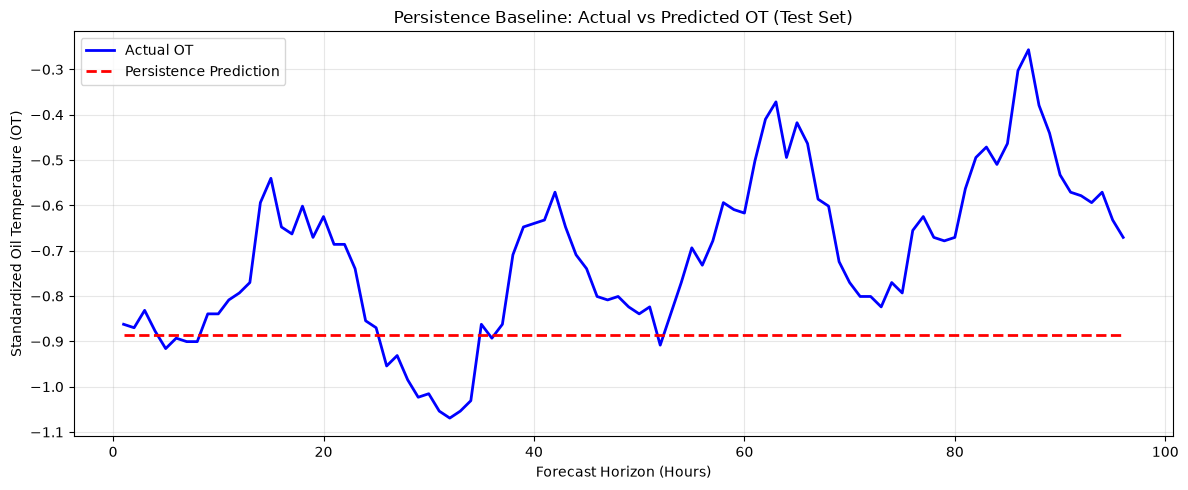

In [5]:
# Select the first sample from the test dataset
sample_index = 0

# Extract the input sequence
X_sample = X_test[sample_index:sample_index + 1]

# Extract actual future OT values
actual = y_test[sample_index].numpy()

# Generate Persistence predictions
predicted = persistence_forecast(
    X_sample,
    target_index=ot_index,
    pred_len=pred_len
).squeeze(0).numpy()

# Create time steps
hours = np.arange(1, pred_len + 1)

# Plot actual vs predicted values
plt.figure(figsize=(12, 5))

plt.plot(
    hours,
    actual,
    label="Actual OT",
    color="blue",
    linewidth=2
)

plt.plot(
    hours,
    predicted,
    label="Persistence Prediction",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Persistence Baseline: Actual vs Predicted OT (Test Set)")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("Standardized Oil Temperature (OT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()